### File Descriptors

A **File Descriptor (FD)** is an integer that the operating system uses to identify I/O resources such as files, sockets, and pipes.

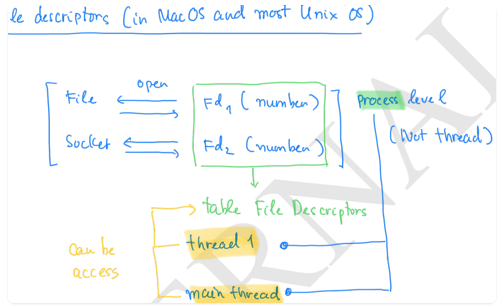

Each process exist an unique talbe call **File Descriptor Talbe**. It's like an array:

```python
# Standard FDs are reserved
FD 0 = stdin  (Standard Input)
FD 1 = stdout (Standard Output)
FD 2 = stderr (Standard Error)
FD 3+ = User-opened files, sockets, pipes...

For example, if we read like this `read(1, buffer, 1024)` -> Kernel take a look at the FD Table and see index 1 -> Read data from it.

But FD not like a bridge that point `A -> B + B -> C = A -> C`. Each operation has a different FD

**Listing them**:

```python 
import os

# Method 1: Using /dev/fd (MacOS/Unix)
fds = os.listdir("/dev/fd")
print(fds)  # ['0', '1', '2', '3', ...]

# Method 2: Using os.fstat()
open_fds = []
for fd in range(0, 1024):
    try:
        os.fstat(fd)
        open_fds.append(fd)
    except OSError:
        pass
print(open_fds)

**Common FD Types**:

```python
import stat

# Check file descriptor type
mode = os.fstat(fd).st_mode

stat.S_ISREG(mode)  # Regular file
stat.S_ISDIR(mode)  # Directory
stat.S_ISCHR(mode)  # Character device
stat.S_ISBLK(mode)  # Block device
stat.S_ISFIFO(mode) # Pipe
stat.S_ISSOCK(mode) # Socket
stat.S_ISLNK(mode)  # Symlink

***Important***
- FDs are managed at the Process level, not Thread level
- Threads within the same process share the FD table
- Use mutex/lock to avoid race conditions